In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import category_encoders as ce

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

e:\anaconda\Lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [2]:
df = pd.read_csv(r"D:\NTI Machine\Preprocessing\House_Rent_Dataset.csv")

### Real Estate Dataset Column Descriptions

* **Index (Unnamed First Column)**: The sequential row number identifying each individual record or listing in the dataset[cite: 1].
* **Posted On**: The date when the rental property listing was originally published online[cite: 1].
* **BHK**: The configuration of the property in terms of Bedrooms, Hall, and Kitchen (e.g., 1, 2, or 3 BHK)[cite: 1].
* **Rent**: The monthly rental price for the property[cite: 1].
* **Size**: The total area of the property (typically measured in square feet), with some records showing missing values as `NaN`[cite: 1].
* **Floor**: The specific floor level of the property relative to the total number of floors in the building (e.g., "Ground out of 2" or "1 out of 3")[cite: 1].
* **Area Type**: The measurement category used for the property size, such as "Super Area" or "Carpet Area"[cite: 1].
* **Area Locality**: The specific neighborhood, district, or local area where the property is located[cite: 1].
* **City**: The city where the rental listing is situated (shown as Kolkata across these rows)[cite: 1].
* **Furnishing Status**: The level of furnishing provided in the property, such as "Unfurnished" or "Semi-Furnished"[cite: 1].
* **Tenant Preferred**: The landlord's preference regarding who can rent the property, such as "Bachelors" or "Bachelors/Family"[cite: 1].
* **Bathroom**: The number of bathrooms available in the property, with some entries displaying missing values as `NaN`[cite: 1].
* **Point of Contact**: Indicates who manages inquiries for the listing, typically listed as "Contact Owner" or "Contact Agent"[cite: 1].


In [3]:
df.head(10)

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner
5,4/29/2022,2,7000.0,600.0,Ground out of 1,Super Area,Thakurpukur,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
6,6/21/2022,2,10000.0,700.0,Ground out of 4,Super Area,Malancha,Kolkata,Unfurnished,Bachelors,2.0,Contact Agent
7,6/21/2022,1,5000.0,250.0,1 out of 2,Super Area,Malancha,Kolkata,Unfurnished,Bachelors,1.0,Contact Agent
8,6/7/2022,2,26000.0,NaN,1 out of 2,Carpet Area,"Palm Avenue Kolkata, Ballygunge",Kolkata,Unfurnished,Bachelors,NaN,Contact Agent
9,6/20/2022,2,10000.0,1000.0,1 out of 3,Carpet Area,Natunhat,Kolkata,Semi-Furnished,Bachelors/Family,2.0,Contact Owner


In [4]:
df.duplicated().sum()

0

In [5]:
df.isnull().sum()

Posted On            0
BHK                  0
Rent                 5
Size                 8
Floor                0
Area Type            7
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             4
Point of Contact     0
dtype: int64

In [6]:
df.shape

(4746, 12)

In [7]:
df = df.dropna()

In [8]:
df.isnull().sum()

Posted On            0
BHK                  0
Rent                 0
Size                 0
Floor                0
Area Type            0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Point of Contact     0
dtype: int64

In [9]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner
5,4/29/2022,2,7000.0,600.0,Ground out of 1,Super Area,Thakurpukur,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
6,6/21/2022,2,10000.0,700.0,Ground out of 4,Super Area,Malancha,Kolkata,Unfurnished,Bachelors,2.0,Contact Agent


In [10]:
df[['Floor', 'Total Floors']] = df['Floor'].str.split(' out of ', expand=True)

In [11]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Total Floors
0,5/18/2022,2,10000.0,1100.0,Ground,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner,2
2,5/16/2022,2,17000.0,1000.0,1,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner,3
4,5/9/2022,2,7500.0,850.0,1,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner,2
5,4/29/2022,2,7000.0,600.0,Ground,Super Area,Thakurpukur,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner,1
6,6/21/2022,2,10000.0,700.0,Ground,Super Area,Malancha,Kolkata,Unfurnished,Bachelors,2.0,Contact Agent,4


In [12]:
df['Tenant Preferred'].unique()

array(['Bachelors/Family', 'Bachelors', 'Family'], dtype=object)

In [13]:
df['Area Locality'].unique()

array(['Bandel', 'Salt Lake City Sector 2', 'South Dum Dum', ...,
       'BN Reddy Nagar', 'Godavari Homes, Quthbullapur',
       'Manikonda, Hyderabad'], dtype=object)

In [14]:
df['City'].unique()

array(['Kolkata', 'Mumbai', 'Bangalore', 'Delhi', 'Chennai', 'Hyderabad'],
      dtype=object)

In [15]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4726.000000,4.726000e+03,4726.000000,4726.000000
mean,2.084215,3.507959e+04,968.290309,1.967626
std,0.832728,7.825741e+04,634.852453,0.885156
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


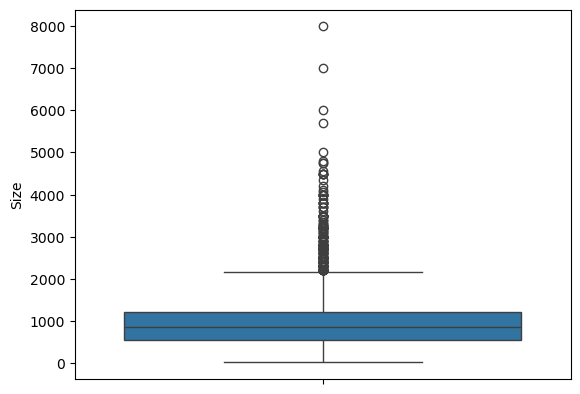

In [16]:
sns.boxplot(data= df, y = df['Size'])
plt.show()

In [17]:
df[df['Size'] < 550]

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Total Floors
7,6/21/2022,1,5000.0,250.0,1,Super Area,Malancha,Kolkata,Unfurnished,Bachelors,1.0,Contact Agent,2
11,6/7/2022,1,5000.0,400.0,1,Carpet Area,Keshtopur,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Agent,1
13,5/9/2022,1,5500.0,375.0,1,Carpet Area,Dum Dum Metro,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Agent,2
22,6/15/2022,1,4000.0,300.0,Ground,Carpet Area,"Garia Station, Garia",Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner,4
24,5/28/2022,1,8000.0,400.0,1,Super Area,Sreebhumi,Kolkata,Semi-Furnished,Bachelors,1.0,Contact Agent,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4706,4/30/2022,1,4500.0,50.0,4,Super Area,Amberpet,Hyderabad,Unfurnished,Bachelors/Family,1.0,Contact Owner,5
4709,5/20/2022,1,6000.0,400.0,1,Super Area,Nagaram,Hyderabad,Unfurnished,Bachelors/Family,1.0,Contact Owner,3
4721,5/12/2022,1,5500.0,40.0,Ground,Super Area,Jagadgiri Gutta,Hyderabad,Unfurnished,Bachelors/Family,1.0,Contact Owner,2
4727,6/28/2022,3,30000.0,214.0,2,Super Area,Jubilee Hills,Hyderabad,Furnished,Bachelors,4.0,Contact Owner,2


In [18]:
print(len(df[df['Size']< 200][['BHK','Size']]))
df[df['Size']< 200][['BHK','Size']]


196


,BHK,Size
50,1,150.0
116,1,20.0
162,1,120.0
170,1,190.0
189,1,44.0
...,...,...
4640,2,110.0
4653,3,10.0
4704,1,150.0
4706,1,50.0


In [19]:
df = df[df['Size'] >= 200]

In [20]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4530.000000,4.530000e+03,4530.000000,4530.000000
mean,2.095364,3.599453e+04,1005.901987,1.984768
std,0.835670,7.976748e+04,621.523373,0.891305
min,1.000000,1.200000e+03,200.000000,1.000000
25%,2.000000,1.000000e+04,600.000000,1.000000
50%,2.000000,1.600000e+04,890.000000,2.000000
75%,3.000000,3.500000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [21]:
df[df['Size'] >1200]

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Total Floors
18,6/9/2022,2,11000.0,2000.0,Ground,Carpet Area,Behala Chowrasta,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner,3
23,6/15/2022,3,6500.0,1600.0,Ground,Super Area,Joka,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner,2
41,5/12/2022,3,12000.0,1500.0,Ground,Carpet Area,Bhadrakali,Kolkata,Furnished,Bachelors,2.0,Contact Owner,2
45,6/6/2022,2,10000.0,1300.0,Ground,Super Area,Kalikapur,Kolkata,Semi-Furnished,Family,2.0,Contact Owner,1
63,6/24/2022,3,30000.0,2000.0,1,Super Area,Naihati,Kolkata,Semi-Furnished,Bachelors/Family,2.0,Contact Owner,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4737,7/7/2022,3,15000.0,1500.0,Lower Basement,Super Area,Almasguda,Hyderabad,Semi-Furnished,Bachelors/Family,3.0,Contact Owner,2
4740,6/2/2022,2,12000.0,1350.0,2,Super Area,Old Alwal,Hyderabad,Unfurnished,Bachelors/Family,2.0,Contact Owner,2
4742,5/15/2022,3,29000.0,2000.0,1,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,3.0,Contact Owner,4
4743,7/10/2022,3,35000.0,1750.0,3,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,3.0,Contact Agent,5


In [22]:
# Look at the top 10 largest properties
df.nlargest(10, 'Size')[['BHK', 'Rent', 'Size', 'Area Locality']]

,BHK,Rent,Size,Area Locality
4185,1,200000.0,8000.0,"Beeramguda, Ramachandra Puram, NH 9"
4457,4,400000.0,7000.0,Jubilee Hills
3622,5,100000.0,6000.0,Navalur
2048,4,250000.0,5700.0,whitefield
1001,4,1200000.0,5000.0,Juhu
1810,4,130000.0,4800.0,whitefield
4241,4,150000.0,4761.0,"Kukatpally, NH 9"
4543,4,200000.0,4761.0,K P H B Phase 4
2236,4,150000.0,4550.0,"Jakkur Plantation, Jakkuru, Bellary Road"
1384,5,600000.0,4500.0,Bandra West


<Axes: >

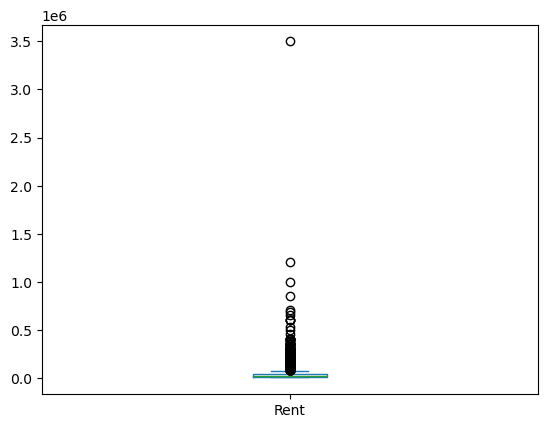

In [23]:
df['Rent'].plot(kind = 'box')

In [24]:
df[df['Rent'] == df['Rent'].max()]

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Total Floors
1837,6/8/2022,3,3500000.0,2500.0,4,Carpet Area,Marathahalli,Bangalore,Semi-Furnished,Bachelors,3.0,Contact Agent,4


In [25]:
df = df[df['Rent'] != df['Rent'].max()]

<Axes: >

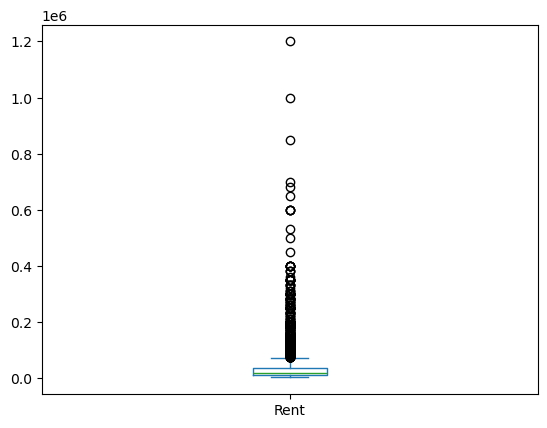

In [26]:
df.Rent.plot(kind = 'box')

<Axes: xlabel='Size', ylabel='Count'>

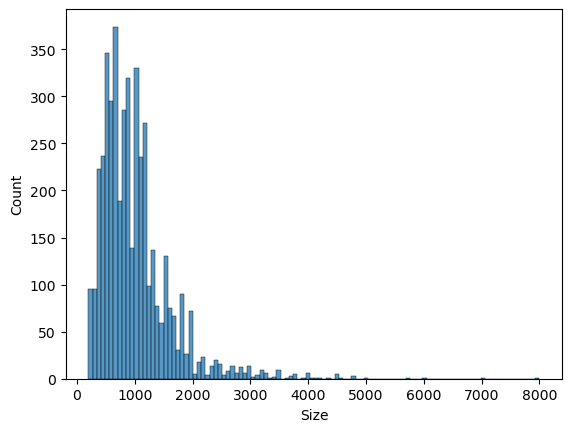

In [27]:
sns.histplot(data = df, x = df['Size'])

In [28]:
df

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Total Floors
0,5/18/2022,2,10000.0,1100.0,Ground,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner,2
2,5/16/2022,2,17000.0,1000.0,1,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner,3
4,5/9/2022,2,7500.0,850.0,1,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner,2
5,4/29/2022,2,7000.0,600.0,Ground,Super Area,Thakurpukur,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner,1
6,6/21/2022,2,10000.0,700.0,Ground,Super Area,Malancha,Kolkata,Unfurnished,Bachelors,2.0,Contact Agent,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4741,5/18/2022,2,15000.0,1000.0,3,Carpet Area,Bandam Kommu,Hyderabad,Semi-Furnished,Bachelors/Family,2.0,Contact Owner,5
4742,5/15/2022,3,29000.0,2000.0,1,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,3.0,Contact Owner,4
4743,7/10/2022,3,35000.0,1750.0,3,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,3.0,Contact Agent,5
4744,7/6/2022,3,45000.0,1500.0,23,Carpet Area,Gachibowli,Hyderabad,Semi-Furnished,Family,2.0,Contact Agent,34


In [29]:
for col in df.select_dtypes("O"):
    print(f"{col} number of uniques: " , df[col].nunique())
    print(f"{col} uniques: ",df[col].unique())
    print("_____________________________________________")

Posted On number of uniques:  81
Posted On uniques:  ['5/18/2022' '5/16/2022' '5/9/2022' '4/29/2022' '6/21/2022' '6/20/2022'
 '6/7/2022' '5/17/2022' '6/9/2022' '7/2/2022' '6/15/2022' '5/28/2022'
 '5/22/2022' '6/25/2022' '6/22/2022' '5/21/2022' '6/26/2022' '5/10/2022'
 '5/12/2022' '6/3/2022' '5/31/2022' '6/24/2022' '4/30/2022' '5/27/2022'
 '6/6/2022' '5/20/2022' '7/3/2022' '5/14/2022' '6/19/2022' '7/6/2022'
 '6/4/2022' '5/5/2022' '5/30/2022' '6/18/2022' '6/8/2022' '5/3/2022'
 '6/1/2022' '5/23/2022' '5/7/2022' '6/27/2022' '5/15/2022' '4/28/2022'
 '6/28/2022' '6/23/2022' '6/13/2022' '6/16/2022' '7/4/2022' '5/4/2022'
 '4/25/2022' '6/10/2022' '5/6/2022' '6/30/2022' '7/1/2022' '6/17/2022'
 '6/11/2022' '5/26/2022' '5/11/2022' '6/12/2022' '6/5/2022' '5/13/2022'
 '6/29/2022' '5/25/2022' '5/24/2022' '5/19/2022' '4/24/2022' '4/23/2022'
 '6/14/2022' '4/27/2022' '5/8/2022' '4/26/2022' '6/2/2022' '5/29/2022'
 '7/7/2022' '7/8/2022' '7/9/2022' '7/5/2022' '5/1/2022' '4/13/2022'
 '5/2/2022' '7/10/2022' 

In [30]:
df['Posted On'] = pd.to_datetime(df['Posted On'])

In [31]:
df

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Total Floors
0,2022-05-18,2,10000.0,1100.0,Ground,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner,2
2,2022-05-16,2,17000.0,1000.0,1,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner,3
4,2022-05-09,2,7500.0,850.0,1,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner,2
5,2022-04-29,2,7000.0,600.0,Ground,Super Area,Thakurpukur,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner,1
6,2022-06-21,2,10000.0,700.0,Ground,Super Area,Malancha,Kolkata,Unfurnished,Bachelors,2.0,Contact Agent,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4741,2022-05-18,2,15000.0,1000.0,3,Carpet Area,Bandam Kommu,Hyderabad,Semi-Furnished,Bachelors/Family,2.0,Contact Owner,5
4742,2022-05-15,3,29000.0,2000.0,1,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,3.0,Contact Owner,4
4743,2022-07-10,3,35000.0,1750.0,3,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,3.0,Contact Agent,5
4744,2022-07-06,3,45000.0,1500.0,23,Carpet Area,Gachibowli,Hyderabad,Semi-Furnished,Family,2.0,Contact Agent,34


In [32]:
df['Year'] = df['Posted On'].dt.year
df['Month'] = df['Posted On'].dt.month
df['Day'] = df['Posted On'].dt.day

In [33]:
df.drop(columns = ['Posted On'],inplace = True)

In [34]:
for col in df.select_dtypes("O"):
    print(f"{col} number of uniques: " , df[col].nunique())
    print(f"{col} uniques: ",df[col].unique())
    print("_____________________________________________")

Floor number of uniques:  54
Floor uniques:  ['Ground' '1' '4' '2' '3' '5' '7' '8' 'Upper Basement' '11'
 'Lower Basement' '6' '14' '43' '13' '18' '17' '9' '19' '60' '34' '12'
 '26' '25' '53' '16' '10' '39' '32' '47' '28' '20' '15' '65' '40' '37'
 '22' '21' '30' '35' '33' '44' '41' '46' '27' '45' '48' '50' '24' '23'
 '29' '49' '36' '76']
_____________________________________________
Area Type number of uniques:  3
Area Type uniques:  ['Super Area' 'Carpet Area' 'Built Area']
_____________________________________________
Area Locality number of uniques:  2171
Area Locality uniques:  ['Bandel' 'Salt Lake City Sector 2' 'South Dum Dum' ... 'BN Reddy Nagar'
 'Godavari Homes, Quthbullapur' 'Manikonda, Hyderabad']
_____________________________________________
City number of uniques:  6
City uniques:  ['Kolkata' 'Mumbai' 'Bangalore' 'Delhi' 'Chennai' 'Hyderabad']
_____________________________________________
Furnishing Status number of uniques:  3
Furnishing Status uniques:  ['Unfurnished' 'S

In [35]:
df['Total Floors'] = df['Total Floors'].astype(float)

In [36]:
df.select_dtypes("O")

,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Point of Contact
0,Ground,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,Contact Owner
2,1,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,Contact Owner
4,1,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,Contact Owner
5,Ground,Super Area,Thakurpukur,Kolkata,Unfurnished,Bachelors/Family,Contact Owner
6,Ground,Super Area,Malancha,Kolkata,Unfurnished,Bachelors,Contact Agent
...,...,...,...,...,...,...,...
4741,3,Carpet Area,Bandam Kommu,Hyderabad,Semi-Furnished,Bachelors/Family,Contact Owner
4742,1,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,Contact Owner
4743,3,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,Contact Agent
4744,23,Carpet Area,Gachibowli,Hyderabad,Semi-Furnished,Family,Contact Agent


In [37]:
oneHotCols = ['Area Type','Furnishing Status','Tenant Preferred','Point of Contact']

In [38]:

ohe = OneHotEncoder(
    sparse_output=False,
    handle_unknown= 'ignore'
).set_output(transform='pandas')

In [39]:
df = pd.concat([df.drop(columns = oneHotCols),ohe.fit_transform(df[oneHotCols])], axis = 1)

In [40]:
df

,BHK,Rent,Size,Floor,Area Locality,City,Bathroom,Total Floors,Year,Month,...,Area Type_Super Area,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
0,2,10000.0,1100.0,Ground,Bandel,Kolkata,2.0,2.0,2022,5,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
2,2,17000.0,1000.0,1,Salt Lake City Sector 2,Kolkata,1.0,3.0,2022,5,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,2,7500.0,850.0,1,South Dum Dum,Kolkata,1.0,2.0,2022,5,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
5,2,7000.0,600.0,Ground,Thakurpukur,Kolkata,2.0,1.0,2022,4,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
6,2,10000.0,700.0,Ground,Malancha,Kolkata,2.0,4.0,2022,6,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4741,2,15000.0,1000.0,3,Bandam Kommu,Hyderabad,2.0,5.0,2022,5,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4742,3,29000.0,2000.0,1,"Manikonda, Hyderabad",Hyderabad,3.0,4.0,2022,5,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4743,3,35000.0,1750.0,3,"Himayath Nagar, NH 7",Hyderabad,3.0,5.0,2022,7,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4744,3,45000.0,1500.0,23,Gachibowli,Hyderabad,2.0,34.0,2022,7,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0


In [41]:
# 1. Define a mapping for the text-based floors
floor_mapping = {
    'Lower Basement': -2,
    'Upper Basement': -1,
    'Ground': 0
}

# 2. Replace the text categories with their numerical equivalents
df['Floor'] = df['Floor'].replace(floor_mapping)

# 3. Convert everything else to numeric (this turns string numbers like '1', '4' into actual integers/floats)
df['Floor'] = pd.to_numeric(df['Floor'])

In [42]:
df

,BHK,Rent,Size,Floor,Area Locality,City,Bathroom,Total Floors,Year,Month,...,Area Type_Super Area,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
0,2,10000.0,1100.0,0,Bandel,Kolkata,2.0,2.0,2022,5,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
2,2,17000.0,1000.0,1,Salt Lake City Sector 2,Kolkata,1.0,3.0,2022,5,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,2,7500.0,850.0,1,South Dum Dum,Kolkata,1.0,2.0,2022,5,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
5,2,7000.0,600.0,0,Thakurpukur,Kolkata,2.0,1.0,2022,4,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
6,2,10000.0,700.0,0,Malancha,Kolkata,2.0,4.0,2022,6,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4741,2,15000.0,1000.0,3,Bandam Kommu,Hyderabad,2.0,5.0,2022,5,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4742,3,29000.0,2000.0,1,"Manikonda, Hyderabad",Hyderabad,3.0,4.0,2022,5,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4743,3,35000.0,1750.0,3,"Himayath Nagar, NH 7",Hyderabad,3.0,5.0,2022,7,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4744,3,45000.0,1500.0,23,Gachibowli,Hyderabad,2.0,34.0,2022,7,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0


In [43]:
df.drop(columns =['Year','Month','Day'],inplace=True)

In [44]:
df

,BHK,Rent,Size,Floor,Area Locality,City,Bathroom,Total Floors,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
0,2,10000.0,1100.0,0,Bandel,Kolkata,2.0,2.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
2,2,17000.0,1000.0,1,Salt Lake City Sector 2,Kolkata,1.0,3.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,2,7500.0,850.0,1,South Dum Dum,Kolkata,1.0,2.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
5,2,7000.0,600.0,0,Thakurpukur,Kolkata,2.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
6,2,10000.0,700.0,0,Malancha,Kolkata,2.0,4.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4741,2,15000.0,1000.0,3,Bandam Kommu,Hyderabad,2.0,5.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4742,3,29000.0,2000.0,1,"Manikonda, Hyderabad",Hyderabad,3.0,4.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4743,3,35000.0,1750.0,3,"Himayath Nagar, NH 7",Hyderabad,3.0,5.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4744,3,45000.0,1500.0,23,Gachibowli,Hyderabad,2.0,34.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0


In [45]:
df.dropna(inplace=True)

In [46]:
df.isnull().sum()

BHK                                  0
Rent                                 0
Size                                 0
Floor                                0
Area Locality                        0
City                                 0
Bathroom                             0
Total Floors                         0
Area Type_Built Area                 0
Area Type_Carpet Area                0
Area Type_Super Area                 0
Furnishing Status_Furnished          0
Furnishing Status_Semi-Furnished     0
Furnishing Status_Unfurnished        0
Tenant Preferred_Bachelors           0
Tenant Preferred_Bachelors/Family    0
Tenant Preferred_Family              0
Point of Contact_Contact Agent       0
Point of Contact_Contact Builder     0
Point of Contact_Contact Owner       0
dtype: int64

In [47]:
from sklearn.model_selection import train_test_split


y = df['Rent']

X = df.drop(columns = ['Rent'])



X_train,X_test,y_train,y_test = train_test_split(X,y,test_size= .2,random_state= 10)

encoder = ce.TargetEncoder(cols=['Area Locality','City'])

X_trainEncoded = encoder.fit_transform(X_train,y_train)

X_testEncoded = encoder.transform(X_test)

In [48]:
X_trainEncoded.head()

,BHK,Size,Floor,Area Locality,City,Bathroom,Total Floors,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
147,2,800.0,0,31242.524739,11802.166667,1.0,4.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
2482,2,450.0,1,25368.877126,30893.086420,1.0,4.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2196,1,750.0,1,31177.470502,21217.496340,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3180,2,1250.0,0,31318.866335,20757.504202,2.0,2.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
199,1,710.0,1,30414.004169,11802.166667,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [49]:
X_testEncoded.head()

,BHK,Size,Floor,Area Locality,City,Bathroom,Total Floors,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
3216,2,840.0,0,34718.877072,20757.504202,2.0,3.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3982,2,1100.0,2,34718.877072,21222.963134,2.0,2.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2039,2,1100.0,1,34718.877072,21217.496340,2.0,3.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
951,2,1000.0,6,134348.361094,85356.349020,3.0,10.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2279,1,300.0,2,30574.374022,21217.496340,1.0,3.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [50]:
y_train.head()

147      8000.0
2482    10000.0
2196     7500.0
3180    11500.0
199     24000.0
Name: Rent, dtype: float64

In [51]:
y_test.head()

3216     14000.0
3982     12000.0
2039     14000.0
951     180000.0
2279      8500.0
Name: Rent, dtype: float64

In [52]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# 1. Initialize the feature scaler
scaler_x = StandardScaler()

# 2. Fit and transform X_trainEncoded, then transform X_testEncoded
X_train_scaled = scaler_x.fit_transform(X_trainEncoded)
X_test_scaled = scaler_x.transform(X_testEncoded)

# 3. Initialize and train your Linear Regression model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# 4. Make predictions on the test set
y_pred = model.predict(X_test_scaled)

In [53]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Calculate the evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# 2. Print out the results
print(f"Mean Absolute Error (MAE): {mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 18,220.09
Root Mean Squared Error (RMSE): 45,164.47
R² Score: 0.5084


In [54]:
y = np.log1p(df['Rent'])
X = df.drop(columns = ['Rent'])

In [55]:
x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=.2,random_state= 10)

In [56]:
x_train


,BHK,Size,Floor,Area Locality,City,Bathroom,Total Floors,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
147,2,800.0,0,Vip Road,Kolkata,1.0,4.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
2482,2,450.0,1,Laxmi Nagar,Delhi,1.0,4.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2196,1,750.0,1,Bettadasanapura,Bangalore,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3180,2,1250.0,0,S.Kolathur,Chennai,2.0,2.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
199,1,710.0,1,Salt Lake City Sector 1,Kolkata,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2049,1,625.0,2,"Hsr Layout Sector 2, HSR Layout",Bangalore,1.0,4.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
1211,2,750.0,4,"vanamali chs ghatla, Ghatla",Mumbai,2.0,20.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
3615,2,700.0,1,Maduravoyal,Chennai,2.0,2.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1376,2,900.0,12,"Challenger Tower, Thakur Village, Kandivali East",Mumbai,2.0,25.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


In [57]:
x_test

,BHK,Size,Floor,Area Locality,City,Bathroom,Total Floors,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
3216,2,840.0,0,"Krishna Nagar-Chromepet, Chromepet",Chennai,2.0,3.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3982,2,1100.0,2,"Balapur X road,Triveni nagar",Hyderabad,2.0,2.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2039,2,1100.0,1,Kyalasanahalli,Bangalore,2.0,3.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
951,2,1000.0,6,Bandra West,Mumbai,3.0,10.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2279,1,300.0,2,Bommanahalli,Bangalore,1.0,3.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1487,2,590.0,7,"Saaga Mrunali CHS, Shantivan",Mumbai,2.0,12.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
4732,2,900.0,0,Vinayaka Nagar,Hyderabad,1.0,2.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
455,2,700.0,0,Behala,Kolkata,1.0,2.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4237,2,1200.0,1,Chintalakunta,Hyderabad,2.0,2.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0


In [58]:
encoder = ce.TargetEncoder(['Area Locality','City'])

In [59]:
x_train = encoder.fit_transform(x_train,y_train)
x_test = encoder.transform(x_test)

In [60]:
x_train

,BHK,Size,Floor,Area Locality,City,Bathroom,Total Floors,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
147,2,800.0,0,9.777314,9.163451,1.0,4.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
2482,2,450.0,1,9.617914,9.926727,1.0,4.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2196,1,750.0,1,9.768918,9.627046,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3180,2,1250.0,0,9.808211,9.636729,2.0,2.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
199,1,710.0,1,9.882002,9.163451,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2049,1,625.0,2,9.889848,9.627046,1.0,4.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
1211,2,750.0,4,10.020838,10.928745,2.0,20.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
3615,2,700.0,1,9.782134,9.636729,2.0,2.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1376,2,900.0,12,9.999236,10.928745,2.0,25.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


In [61]:
x_test

,BHK,Size,Floor,Area Locality,City,Bathroom,Total Floors,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
3216,2,840.0,0,9.895472,9.636729,2.0,3.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3982,2,1100.0,2,9.895472,9.679248,2.0,2.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2039,2,1100.0,1,9.895472,9.627046,2.0,3.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
951,2,1000.0,6,11.317326,10.928745,3.0,10.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2279,1,300.0,2,9.794883,9.627046,1.0,3.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1487,2,590.0,7,9.895472,10.928745,2.0,12.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
4732,2,900.0,0,9.895472,9.679248,1.0,2.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
455,2,700.0,0,9.675580,9.163451,1.0,2.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4237,2,1200.0,1,9.830063,9.679248,2.0,2.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0


In [62]:
scaler = StandardScaler()
x_train[['Area Locality','City','Size']] = scaler.fit_transform(x_train[['Area Locality','City','Size']])
x_test[['Area Locality','City','Size']] = scaler.transform(x_test[['Area Locality','City','Size']])

In [63]:
x_train.head()

,BHK,Size,Floor,Area Locality,City,Bathroom,Total Floors,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
147,2,-0.323235,0,-0.645545,-1.293143,1.0,4.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
2482,2,-0.892963,1,-1.478078,0.055213,1.0,4.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2196,1,-0.404624,1,-0.689396,-0.474185,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3180,2,0.409273,0,-0.484171,-0.457080,2.0,2.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
199,1,-0.469736,1,-0.098767,-1.293143,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [64]:
x_test.head()

,BHK,Size,Floor,Area Locality,City,Bathroom,Total Floors,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
3216,2,-0.258123,0,-0.028415,-0.457080,2.0,3.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3982,2,0.165104,2,-0.028415,-0.381967,2.0,2.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2039,2,0.165104,1,-0.028415,-0.474185,2.0,3.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
951,2,0.002324,6,7.397814,1.825315,3.0,10.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2279,1,-1.137132,2,-0.553783,-0.474185,1.0,3.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [65]:
y_train

147      8.987322
2482     9.210440
2196     8.922792
3180     9.350189
199     10.085851
          ...    
2049     9.852247
1211    10.859018
3615     9.392745
1376    10.434145
1320    11.289794
Name: Rent, Length: 3620, dtype: float64

In [66]:
y_test

3216     9.546884
3982     9.392745
2039     9.546884
951     12.100718
2279     9.047939
          ...    
1487    10.373522
4732     8.853808
455      9.047939
4237     9.680406
1238    12.206078
Name: Rent, Length: 905, dtype: float64

In [67]:
modelp = LinearRegression()

In [68]:
modelp.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](19,)","[ 0.19, 0.2 , 0. ,..., 0.32,-0.35, 0.03]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](19,)","['BHK','Size','Floor',...,'Point of Contact_Contact Agent', 'Point of Contact_Contact Builder','Point of Contact_Contact Owner']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9.084
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,19
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,15


In [69]:
yPred = modelp.predict(x_test)

In [70]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Calculate the evaluation metrics
mae = mean_absolute_error(y_test, yPred)
mse = mean_squared_error(y_test, yPred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, yPred)

# 2. Print out the results
print(f"Mean Absolute Error (MAE): {mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 0.28
Root Mean Squared Error (RMSE): 0.39
R² Score: 0.8364


In [71]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    # "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [72]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

In [73]:
from tqdm import tqdm

  0%|          | 0/14 [00:00<?, ?it/s]

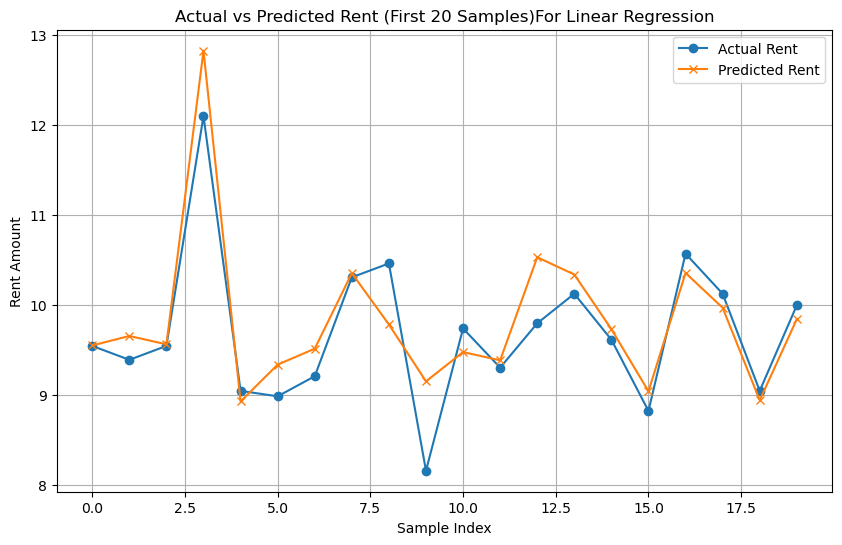

  7%|▋         | 1/14 [00:00<00:04,  3.03it/s]

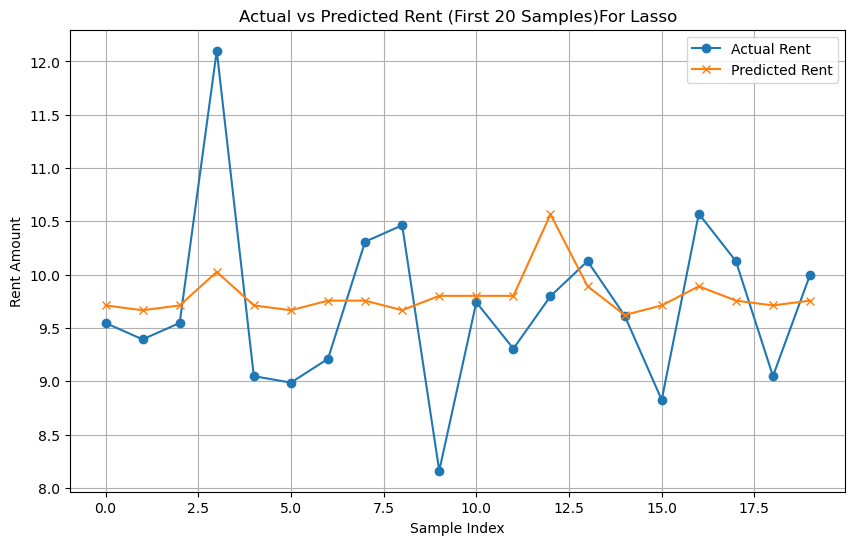

 14%|█▍        | 2/14 [00:00<00:04,  2.84it/s]

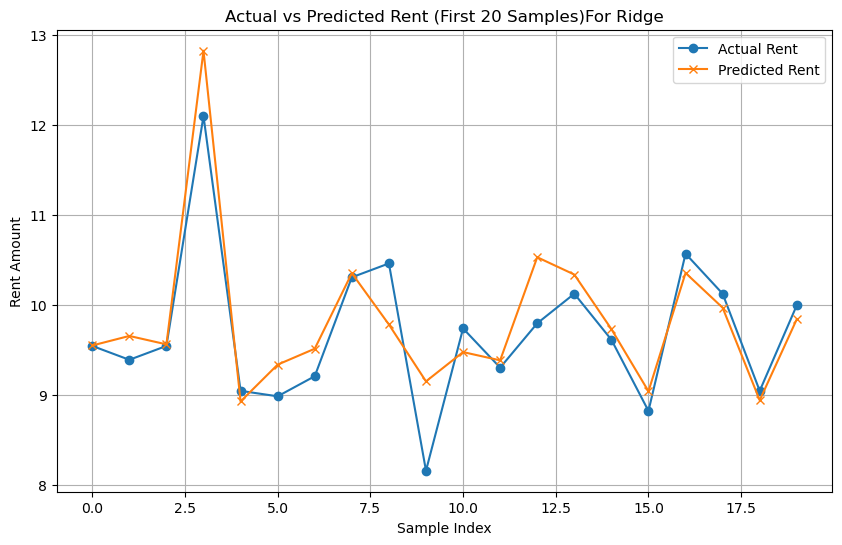

 21%|██▏       | 3/14 [00:01<00:03,  2.91it/s]e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "e:\anaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, ar

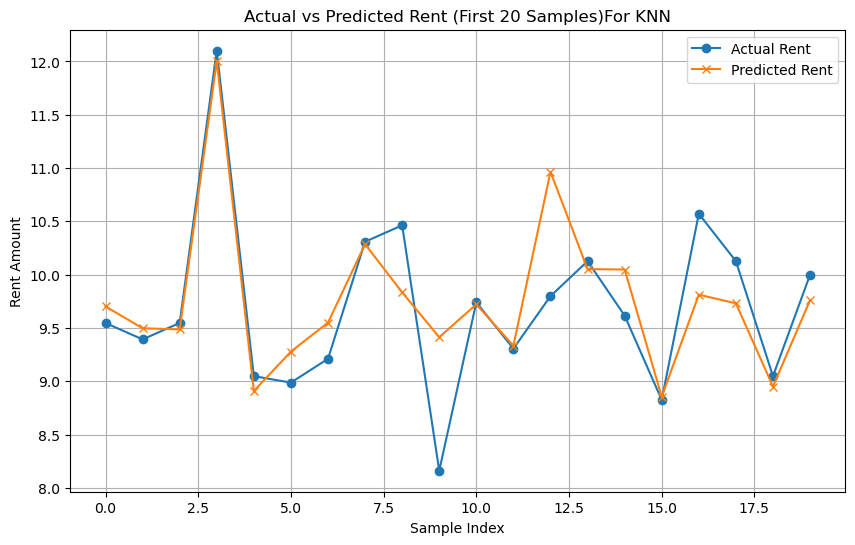

 29%|██▊       | 4/14 [00:01<00:05,  1.94it/s]

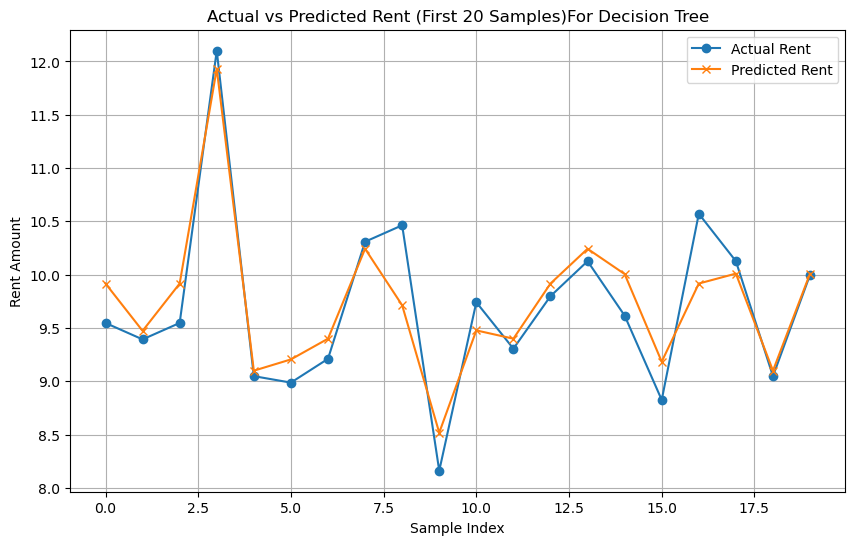

 36%|███▌      | 5/14 [00:02<00:04,  2.20it/s]

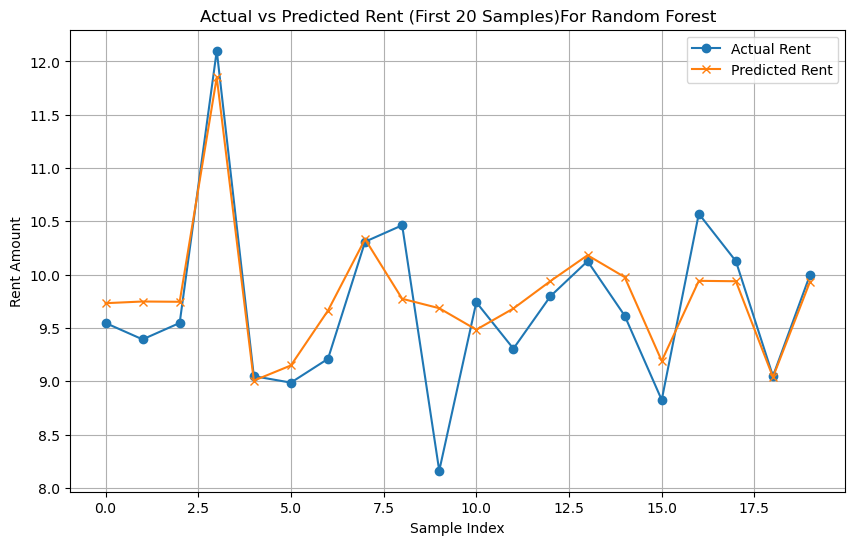

 43%|████▎     | 6/14 [00:02<00:04,  1.73it/s]

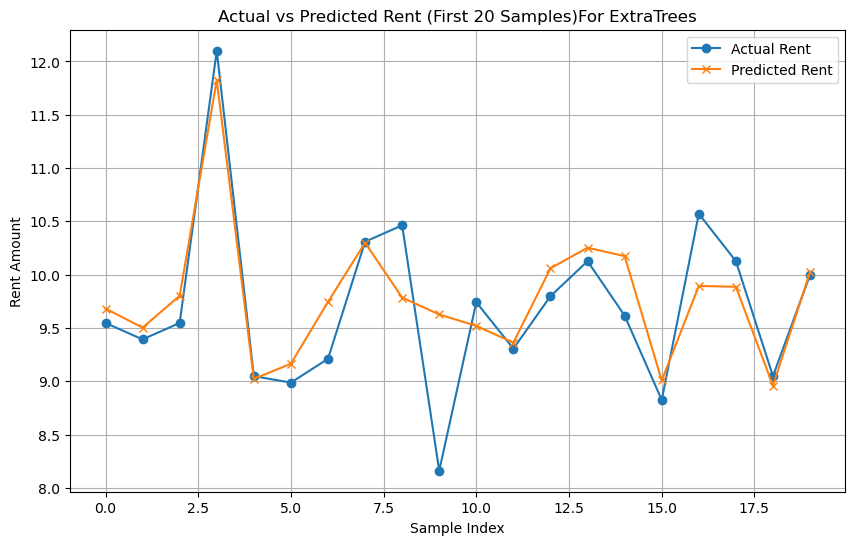

 50%|█████     | 7/14 [00:04<00:06,  1.07it/s]

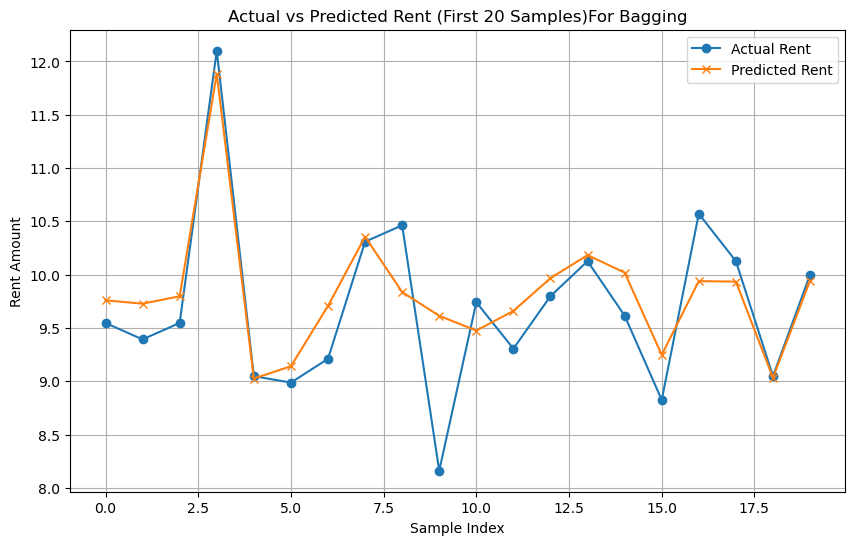

 57%|█████▋    | 8/14 [00:05<00:05,  1.09it/s]

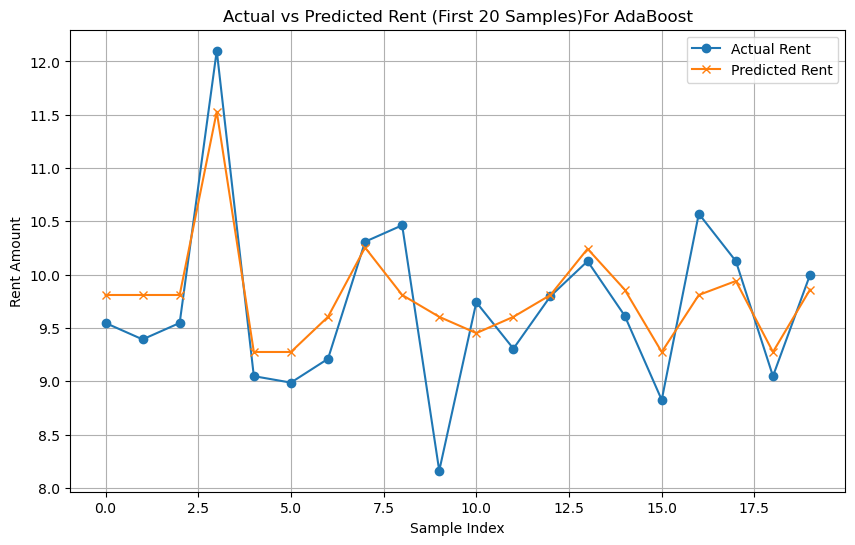

 64%|██████▍   | 9/14 [00:05<00:03,  1.37it/s]

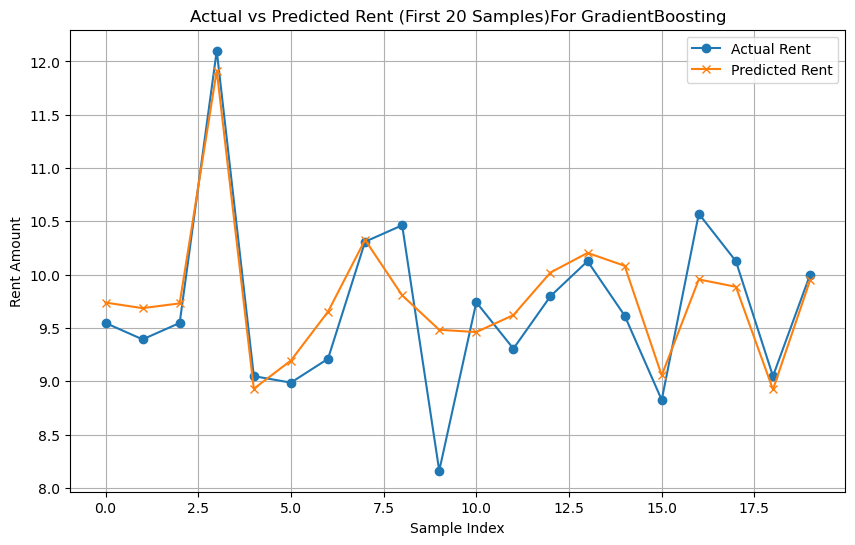

 71%|███████▏  | 10/14 [00:06<00:02,  1.36it/s]

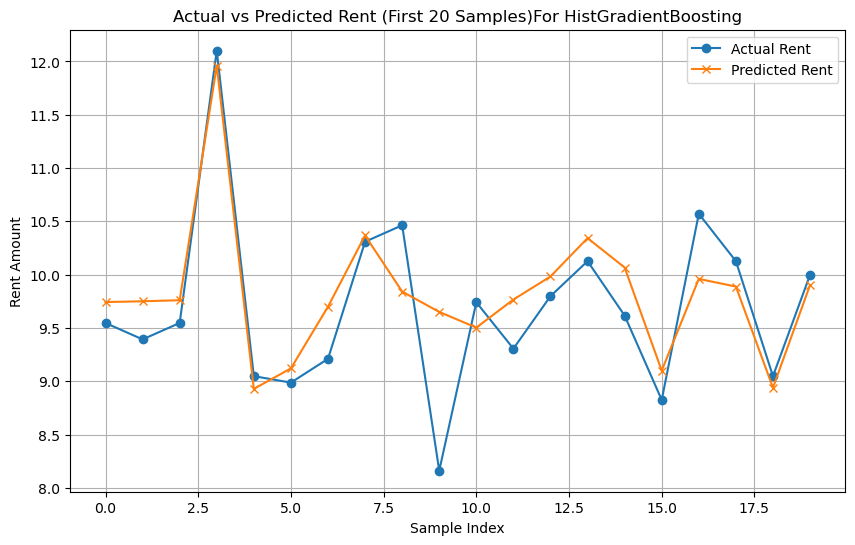

 79%|███████▊  | 11/14 [00:08<00:02,  1.06it/s]

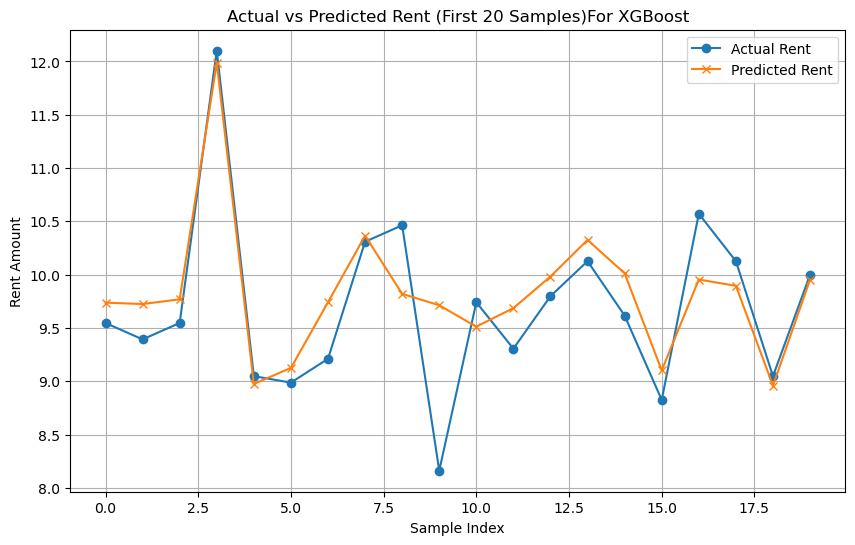

 86%|████████▌ | 12/14 [00:08<00:01,  1.20it/s]

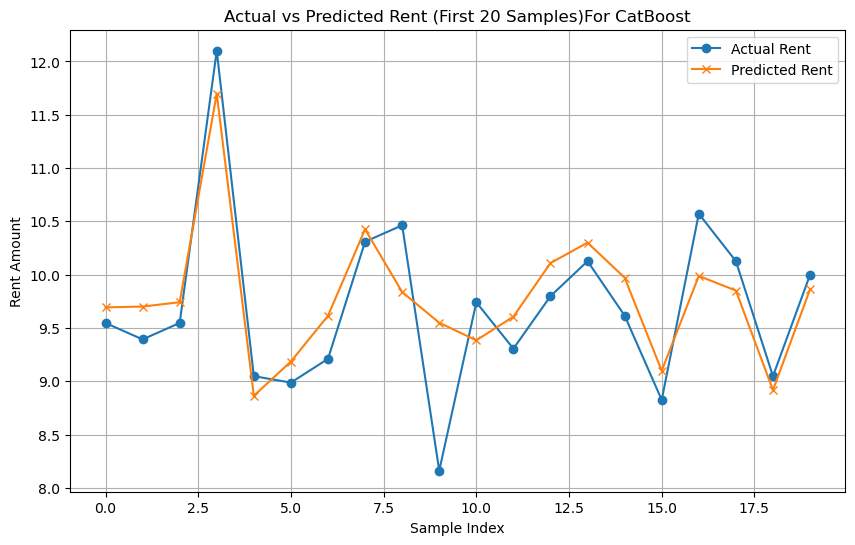

 93%|█████████▎| 13/14 [00:09<00:00,  1.23it/s]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001865 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 641
[LightGBM] [Info] Number of data points in the train set: 3620, number of used features: 17
[LightGBM] [Info] Start training from score 9.895472


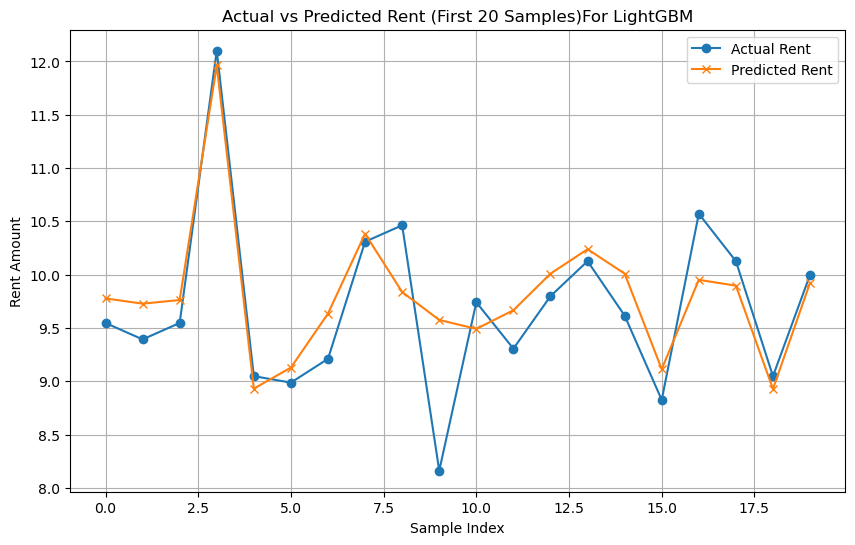

100%|██████████| 14/14 [00:10<00:00,  1.39it/s]


In [74]:
errors={}

for model_name , model in tqdm(models.items()):
    model.fit(x_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, x_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, x_test, y_test)
    
    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(x_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [75]:
errors = pd.DataFrame(errors)
errors

,Linear Regression,Lasso,Ridge,KNN,Decision Tree,Random Forest,ExtraTrees,Bagging,AdaBoost,GradientBoosting,HistGradientBoosting,XGBoost,CatBoost,LightGBM
MAE Train,0.257395,0.591615,0.257453,0.233784,0.119204,0.118242,0.000310,0.118909,0.256348,0.182233,0.140929,0.122584,0.181720,0.140654
MAE Test,0.282012,0.626025,0.282007,0.318782,0.416727,0.389662,0.343347,0.389875,0.444518,0.368419,0.359734,0.362451,0.365942,0.354895
MSE Train,0.122245,0.593103,0.122257,0.100937,0.030731,0.026393,0.000024,0.027027,0.109597,0.059189,0.037666,0.027716,0.058209,0.037865
MSE Test,0.150639,0.688827,0.150636,0.196792,0.321045,0.292925,0.222138,0.289534,0.346758,0.252736,0.249915,0.257170,0.266468,0.246459
RMSE Train,0.349635,0.770132,0.349653,0.317706,0.175303,0.162458,0.004879,0.164400,0.331054,0.243287,0.194077,0.166481,0.241265,0.194589
RMSE Test,0.388122,0.829956,0.388119,0.443612,0.566608,0.541225,0.471316,0.538083,0.588862,0.502728,0.499915,0.507119,0.516205,0.496446
R2 Train,0.859030,0.316045,0.859015,0.883601,0.964561,0.969564,0.999973,0.968833,0.873615,0.931745,0.956564,0.968039,0.932875,0.956335
R2 Test,0.836428,0.252034,0.836431,0.786313,0.651392,0.681926,0.758790,0.685609,0.623471,0.725566,0.728629,0.720751,0.710654,0.732382
